# Bank Marketing: Comparative Analysis of Classification Algorithms

**Subject:** Fundamentals of Data Science  
**Dataset:** UCI Bank Marketing (`bank-full.csv`)  
**Student:** Md. Siddiq Juber  
**Roll No.:** 160124733363  
**Section:** CSE-3  
**Year:** III Year, B.E. CSE  
**Faculty:** Smt. S. Durga Devi

## Objective
Predict whether a customer will subscribe to a term deposit (`y = yes`) and compare Logistic Regression, Decision Tree, K-Nearest Neighbours (KNN), and Random Forest using the same stratified 80:20 split.

**Important design decision:** `duration` is excluded from all primary models because the call duration is not available before the call begins. Including it would make the prediction unrealistic for pre-contact targeting.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / 'bank-full.csv').exists():
    # Allows execution when the notebook is opened from its parent folder.
    ROOT = ROOT / 'bank-marketing-case-study'
DATA_PATH = ROOT / 'bank-full.csv'
FIG_DIR, OUT_DIR, MODEL_DIR = ROOT / 'figures', ROOT / 'outputs', ROOT / 'models'
for folder in (FIG_DIR, OUT_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
print('Project directory:', ROOT.resolve())

Project directory: C:\Users\siddi\Downloads\Bank_Marketing_Classification_Case_Study_Project\bank-marketing-case-study


## 2. Load and understand the dataset
The file is semicolon-delimited, so it is loaded with `sep=';'`. The target `y` is yes/no.

In [2]:
df = pd.read_csv(DATA_PATH, sep=';')
print(f'Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head(10))
print('Column data types:')
display(df.dtypes.rename('dtype').to_frame())
print('Numerical descriptive statistics:')
display(df.describe().T)
print('Categorical descriptive statistics:')
display(df.describe(include='object').T)
print('Missing values per column:')
display(df.isna().sum().rename('missing_count').to_frame())
print('Exact duplicate rows:', int(df.duplicated().sum()))

Dataset shape: 45,211 rows x 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


Column data types:


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


Numerical descriptive statistics:


...

Categorical descriptive statistics:


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


Missing values per column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Exact duplicate rows: 0


## 3. Target distribution and unknown-category audit
The dataset uses literal values such as `unknown` in some categorical columns. These are retained as categories rather than silently converted to missing values.

,customers,percentage
y,,
no,39922,88.3
yes,5289,11.7


,literal_unknown_count
job,288
marital,0
education,1857
default,0
housing,0
loan,0
contact,13020
month,0
poutcome,36959
y,0


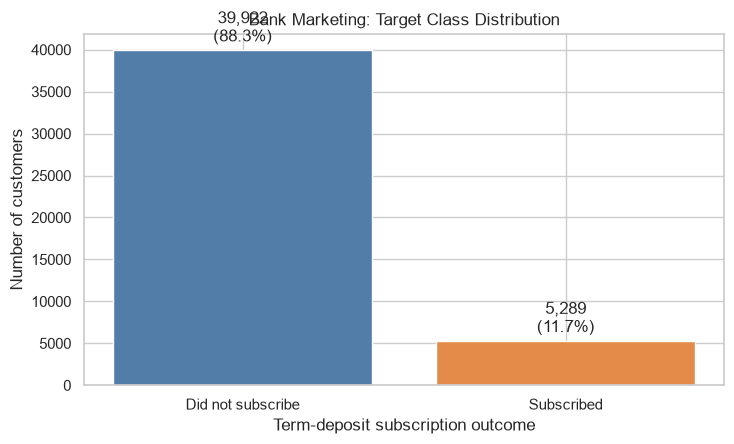

In [3]:
target_counts = df['y'].value_counts().reindex(['no', 'yes'])
target_summary = pd.DataFrame({'customers': target_counts,
                               'percentage': (target_counts / len(df) * 100).round(2)})
display(target_summary)
unknown_counts = {c: int((df[c].astype(str).str.lower() == 'unknown').sum())
                  for c in df.select_dtypes(include='object').columns}
display(pd.Series(unknown_counts, name='literal_unknown_count').to_frame())
fig, ax = plt.subplots(figsize=(7.5, 4.6))
bars = ax.bar(['Did not subscribe', 'Subscribed'], target_counts.values, color=['#527da8', '#e38b48'])
ax.set_title('Bank Marketing: Target Class Distribution')
ax.set_xlabel('Term-deposit subscription outcome')
ax.set_ylabel('Number of customers')
ax.bar_label(bars, labels=[f'{v:,}\n({v / len(df):.1%})' for v in target_counts.values], padding=3)
fig.tight_layout(); fig.savefig(FIG_DIR / 'target_distribution.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

## 4. Exploratory data analysis
Rates are descriptive, not causal. Category groups may differ in other ways not controlled for in these charts.

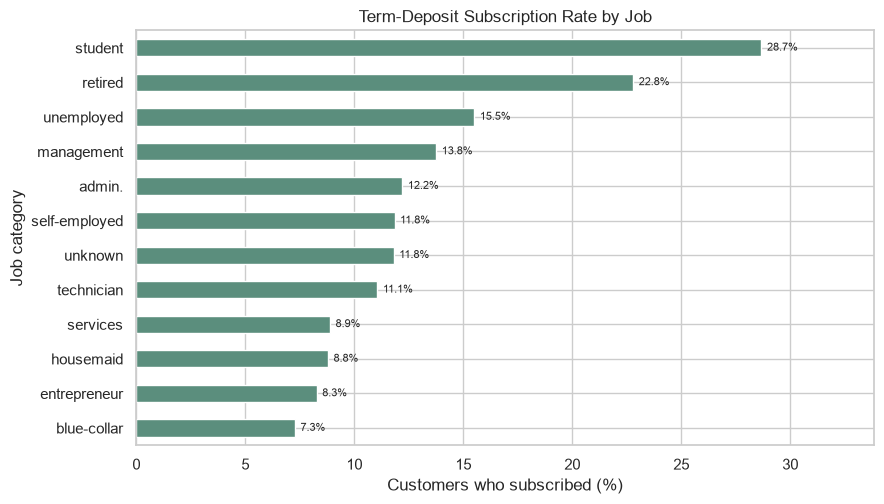

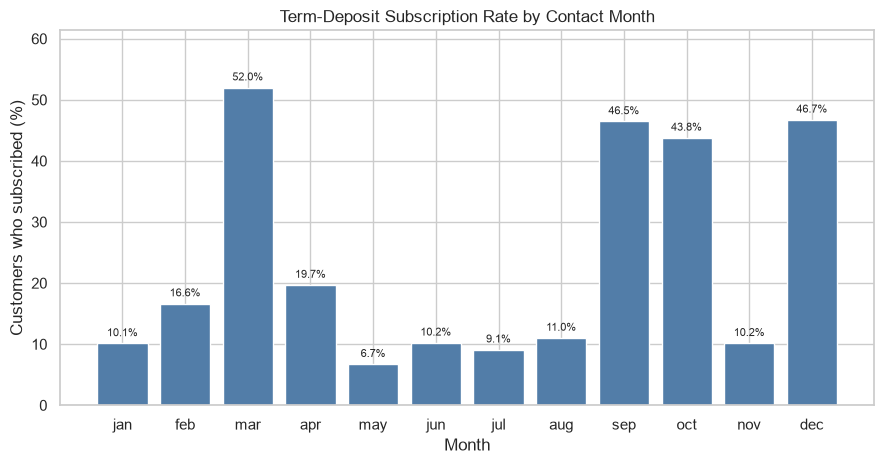

In [4]:
eda = df.copy()
eda['subscribed'] = (eda['y'] == 'yes').astype(int)
job_rates = eda.groupby('job', observed=False)['subscribed'].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(9, 5.2))
job_rates.plot(kind='barh', ax=ax, color='#5b8e7d')
ax.set_title('Term-Deposit Subscription Rate by Job')
ax.set_xlabel('Customers who subscribed (%)'); ax.set_ylabel('Job category')
for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%', (p.get_width(), p.get_y()+p.get_height()/2), xytext=(4,0), textcoords='offset points', va='center', fontsize=8)
ax.set_xlim(0, float(job_rates.max())*1.18)
fig.tight_layout(); fig.savefig(FIG_DIR / 'subscription_by_job.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
month_rates = eda.groupby('month', observed=False)['subscribed'].mean().reindex(month_order) * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(month_rates.index, month_rates.values, color='#527da8')
ax.set_title('Term-Deposit Subscription Rate by Contact Month')
ax.set_xlabel('Month'); ax.set_ylabel('Customers who subscribed (%)')
for i, v in enumerate(month_rates.values): ax.text(i, v + 0.8, f'{v:.1f}%', ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, float(month_rates.max())*1.18)
fig.tight_layout(); fig.savefig(FIG_DIR / 'subscription_by_month.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

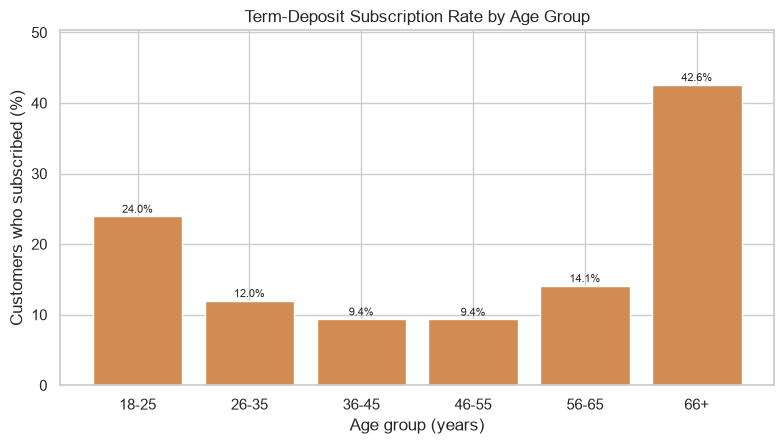

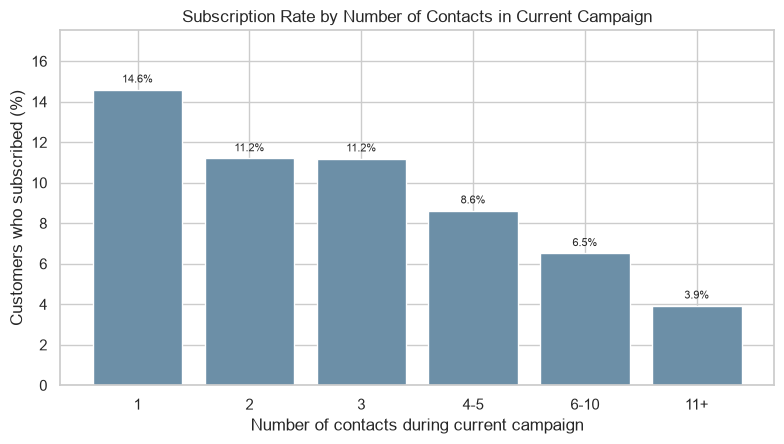

In [5]:
age_bins = pd.cut(df['age'], bins=[17,25,35,45,55,65,100], right=True, include_lowest=True,
                   labels=['18-25','26-35','36-45','46-55','56-65','66+'])
age_rates = pd.DataFrame({'age_group': age_bins, 'subscribed': (df['y']=='yes').astype(int)}).groupby('age_group', observed=False)['subscribed'].mean()*100
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.bar(age_rates.index.astype(str), age_rates.values, color='#d28b52')
ax.set_title('Term-Deposit Subscription Rate by Age Group')
ax.set_xlabel('Age group (years)'); ax.set_ylabel('Customers who subscribed (%)')
for i,v in enumerate(age_rates.values): ax.text(i, v+0.5, f'{v:.1f}%', ha='center', fontsize=8)
ax.set_ylim(0, float(age_rates.max())*1.18)
fig.tight_layout(); fig.savefig(FIG_DIR / 'subscription_by_age_group.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

campaign_bins = pd.cut(df['campaign'], bins=[0,1,2,3,5,10,100], include_lowest=True,
                       labels=['1','2','3','4-5','6-10','11+'])
campaign_rates = pd.DataFrame({'campaign_group': campaign_bins, 'subscribed': (df['y']=='yes').astype(int)}).groupby('campaign_group', observed=False)['subscribed'].mean()*100
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.bar(campaign_rates.index.astype(str), campaign_rates.values, color='#6c8fa7')
ax.set_title('Subscription Rate by Number of Contacts in Current Campaign')
ax.set_xlabel('Number of contacts during current campaign'); ax.set_ylabel('Customers who subscribed (%)')
for i, v in enumerate(campaign_rates.values): ax.text(i, v+0.35, f'{v:.1f}%', ha='center', fontsize=8)
ax.set_ylim(0, float(campaign_rates.max())*1.20)
fig.tight_layout(); fig.savefig(FIG_DIR / 'subscription_by_campaign_count.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

### Preliminary evidence-based observations
1. The target is imbalanced: approximately 88.3% did not subscribe and 11.7% subscribed. Accuracy alone can therefore make a weak model look good.
2. Subscription rates vary by job and month. These patterns can help campaign planning, but they are descriptive associations and should not be interpreted as causal effects.
3. Subscription rates vary by age group and campaign contact count. Repeated contact is not automatically better; campaign policy should be assessed using both conversion and contact cost/experience.

## 5. Preprocessing and train-test split
The outcome is converted to 1 for `yes` and 0 for `no`. The `duration` predictor is deliberately omitted. Numerical features are median-imputed and standardized; categorical features are imputed with the most frequent category and one-hot encoded. The preprocessing pipeline is fitted on training data only.

In [6]:
y = (df['y'].astype(str).str.lower() == 'yes').astype(int)
X = df.drop(columns=['y', 'duration'])  # duration excluded for pre-contact prediction
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print(f'Training rows: {len(X_train):,}; testing rows: {len(X_test):,}')
print(f'Target yes-rate - train: {y_train.mean():.2%}; test: {y_test.mean():.2%}')
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scaler', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipe, numeric_features),
    ('categorical', categorical_pipe, categorical_features),
], remainder='drop')

Training rows: 36,168; testing rows: 9,043
Target yes-rate - train: 11.70%; test: 11.70%
Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 6. Train four classification models
All four models use the same split, features, target, and preprocessing. The specified settings are kept fixed for a transparent comparison; this is not an exhaustive hyperparameter search.

In [7]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1500, solver='liblinear', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=5),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1),
    'Random Forest': RandomForestClassifier(n_estimators=160, min_samples_leaf=2, max_features='sqrt', random_state=RANDOM_STATE, n_jobs=-1),
}
trained_models, predictions = {}, {}
rows = []
for name, estimator in models.items():
    print('Training', name)
    pipeline = Pipeline([('preprocess', preprocessor), ('model', estimator)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    trained_models[name] = pipeline
    predictions[name] = (pred, prob)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'True Negatives': tn, 'False Positives': fp,
        'False Negatives': fn, 'True Positives': tp,
    })
metrics = pd.DataFrame(rows).sort_values(['F1-score','ROC-AUC'], ascending=False).reset_index(drop=True)
metrics.to_csv(OUT_DIR / 'model_comparison.csv', index=False, float_format='%.6f')
display(metrics.style.format({c: '{:.3f}' for c in ['Accuracy','Precision','Recall','F1-score','ROC-AUC']}))

Training Logistic Regression
Training Decision Tree
Training K-Nearest Neighbours
Training Random Forest


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,True Negatives,False Positives,False Negatives,True Positives
0,Decision Tree,0.870,0.418,0.293,0.345,0.680,7554,431,748,310
1,Random Forest,0.896,0.668,0.218,0.329,0.803,7870,115,827,231
2,K-Nearest Neighbours,0.889,0.576,0.198,0.294,0.714,7831,154,849,209
3,Logistic Regression,0.893,0.664,0.178,0.280,0.772,7890,95,870,188


## 7. Compare accuracy, precision, recall, and F1-score

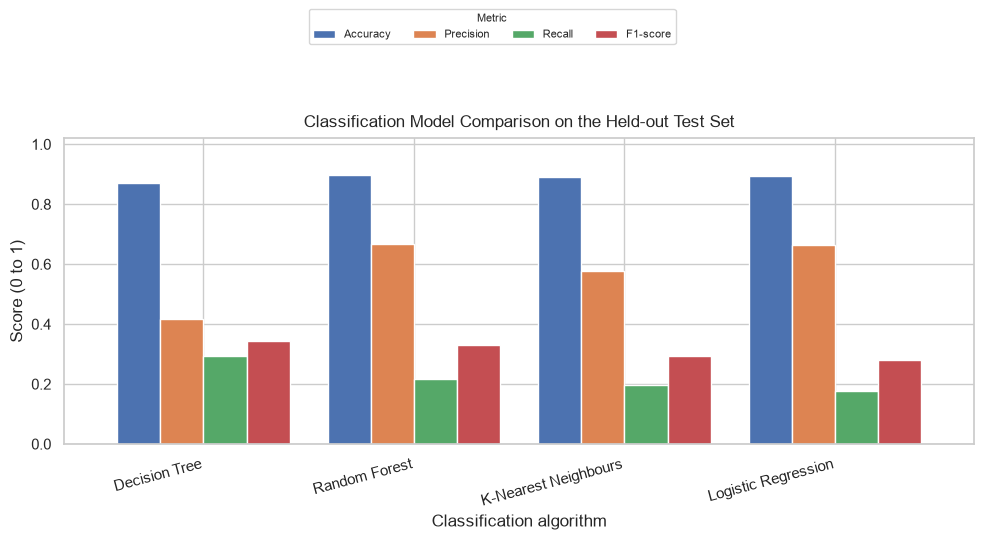

In [8]:
plot_metrics = metrics.set_index('Model')[['Accuracy','Precision','Recall','F1-score']]
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_metrics.plot(kind='bar', ax=ax, width=0.82)
handles, labels = ax.get_legend_handles_labels(); ax.legend_.remove()
fig.legend(handles, labels, title='Metric', loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=4, fontsize=8, title_fontsize=8)
ax.set_title('Classification Model Comparison on the Held-out Test Set', pad=8)
ax.set_xlabel('Classification algorithm'); ax.set_ylabel('Score (0 to 1)')
ax.set_ylim(0, 1.02); plt.xticks(rotation=15, ha='right'); fig.tight_layout(rect=[0, 0, 1, 0.82])
fig.savefig(FIG_DIR / 'model_metrics_comparison.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)

## 8. Confusion matrices and classification reports
For the positive class, a false negative is a subscriber that the model misses; a false positive is a non-subscriber incorrectly prioritized. The relative cost of these errors depends on the bank's contact budget and campaign goals.

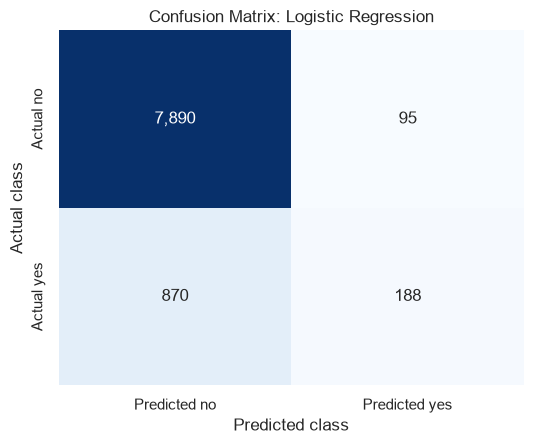

--- Logistic Regression ---
                 precision    recall  f1-score   support

No subscription       0.90      0.99      0.94      7985
   Subscription       0.66      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.86      9043



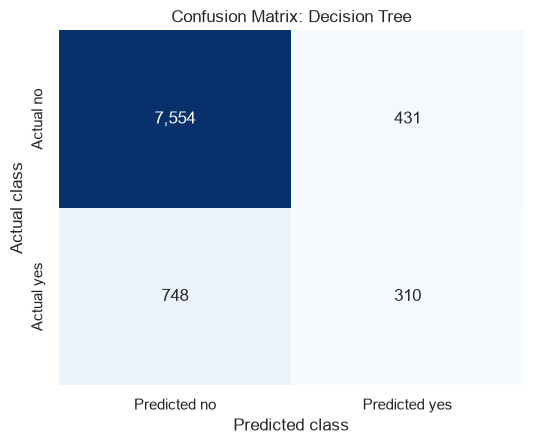

--- Decision Tree ---
                 precision    recall  f1-score   support

No subscription       0.91      0.95      0.93      7985
   Subscription       0.42      0.29      0.34      1058

       accuracy                           0.87      9043
      macro avg       0.66      0.62      0.64      9043
   weighted avg       0.85      0.87      0.86      9043



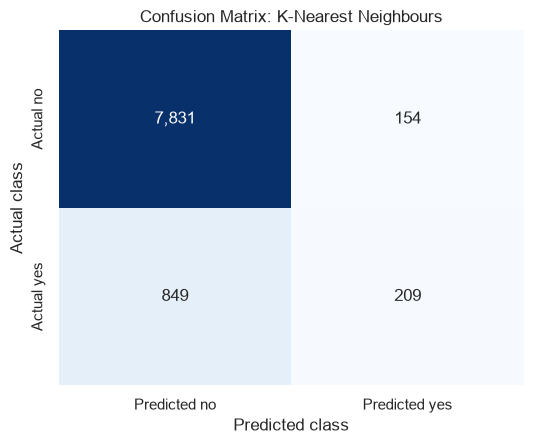

--- K-Nearest Neighbours ---
                 precision    recall  f1-score   support

No subscription       0.90      0.98      0.94      7985
   Subscription       0.58      0.20      0.29      1058

       accuracy                           0.89      9043
      macro avg       0.74      0.59      0.62      9043
   weighted avg       0.86      0.89      0.86      9043



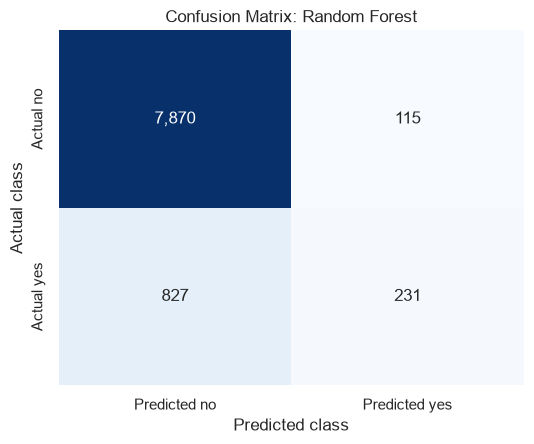

--- Random Forest ---
                 precision    recall  f1-score   support

No subscription       0.90      0.99      0.94      7985
   Subscription       0.67      0.22      0.33      1058

       accuracy                           0.90      9043
      macro avg       0.79      0.60      0.64      9043
   weighted avg       0.88      0.90      0.87      9043



In [9]:
for name, (pred, prob) in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    fig, ax = plt.subplots(figsize=(5.5, 4.6))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
                xticklabels=['Predicted no','Predicted yes'],
                yticklabels=['Actual no','Actual yes'], ax=ax)
    ax.set_title(f'Confusion Matrix: {name}')
    ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class')
    fig.tight_layout()
    safe = name.lower().replace(' ','_').replace('-','')
    fig.savefig(FIG_DIR / f'confusion_matrix_{safe}.png', dpi=170, bbox_inches='tight')
    display(fig); plt.close(fig)
    print(f'--- {name} ---')
    print(classification_report(y_test, pred, target_names=['No subscription','Subscription'], zero_division=0))

## 9. ROC curves and ROC-AUC

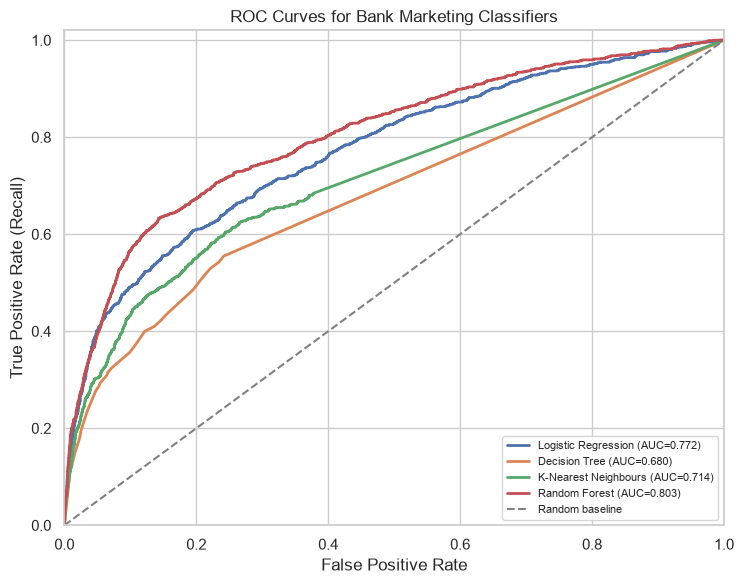

               Model  ROC-AUC
       Decision Tree   0.6797
       Random Forest   0.8027
K-Nearest Neighbours   0.7138
 Logistic Regression   0.7718


In [10]:
fig, ax = plt.subplots(figsize=(7.6, 6))
for name, (pred, prob) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc_value:.3f})')
ax.plot([0,1],[0,1], linestyle='--', color='gray', label='Random baseline')
ax.set_title('ROC Curves for Bank Marketing Classifiers')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate (Recall)')
ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(loc='lower right', fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'roc_curves.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)
print(metrics[['Model','ROC-AUC']].to_string(index=False, float_format=lambda v:f'{v:.4f}'))

## 10. Model selection, findings, and business implications

In [11]:
best_name = str(metrics.iloc[0]['Model'])
best_row = metrics.iloc[0]
print('Selected model (highest F1-score; ROC-AUC tie-breaker):', best_name)
print(best_row[['Accuracy','Precision','Recall','F1-score','ROC-AUC']].to_string())
print('\nThree evidence-based observations:')
print(f"1. {target_counts['yes']:,} of {len(df):,} customers subscribed ({target_counts['yes']/len(df):.1%}); the majority class is 'no'.")
print(f"2. Highest observed job subscription rate: {job_rates.idxmax()} ({job_rates.max():.1f}%).")
print(f"3. Highest observed month subscription rate: {month_rates.idxmax()} ({month_rates.max():.1f}%).")
print('\nCaveat: the best F1 model is not the model with the highest ROC-AUC; Random Forest has the highest ROC-AUC in this run. The choice prioritizes positive-class precision/recall balance at the default 0.5 threshold. Threshold tuning can change this trade-off.')

joblib.dump(trained_models[best_name], MODEL_DIR / 'best_bank_marketing_model.joblib')
(OUT_DIR / 'best_model.json').write_text(json.dumps({
    'best_model_by_f1_then_roc_auc': best_name,
    'selection_criterion': 'Highest test F1-score; ROC-AUC used as a tie-breaker. Accuracy is not used alone because y is imbalanced.',
    'excluded_feature': 'duration',
}, indent=2), encoding='utf-8')
summary = {
    'rows': int(df.shape[0]), 'columns_including_target': int(df.shape[1]),
    'duplicate_rows': int(df.duplicated().sum()), 'missing_cells': int(df.isna().sum().sum()),
    'target_counts': {str(k): int(v) for k,v in df['y'].value_counts().items()},
    'target_percentages': {str(k): float(v) for k,v in (df['y'].value_counts(normalize=True)*100).items()},
    'unknown_category_counts': unknown_counts, 'excluded_features': ['duration'],
    'numeric_features_used': numeric_features, 'categorical_features_used': categorical_features,
    'train_rows': int(len(X_train)), 'test_rows': int(len(X_test)),
}
(OUT_DIR / 'dataset_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Saved results to:', OUT_DIR)
print('Saved final selected pipeline to:', MODEL_DIR / 'best_bank_marketing_model.joblib')

Selected model (highest F1-score; ROC-AUC tie-breaker): Decision Tree
Accuracy     0.869623
Precision    0.418354
Recall       0.293006
F1-score     0.344636
ROC-AUC      0.679677

Three evidence-based observations:
1. 5,289 of 45,211 customers subscribed (11.7%); the majority class is 'no'.
2. Highest observed job subscription rate: student (28.7%).
3. Highest observed month subscription rate: mar (52.0%).

Caveat: the best F1 model is not the model with the highest ROC-AUC; Random Forest has the highest ROC-AUC in this run. The choice prioritizes positive-class precision/recall balance at the default 0.5 threshold. Threshold tuning can change this trade-off.
Saved results to: c:\Users\siddi\Downloads\Bank_Marketing_Classification_Case_Study_Project\bank-marketing-case-study\outputs
Saved final selected pipeline to: c:\Users\siddi\Downloads\Bank_Marketing_Classification_Case_Study_Project\bank-marketing-case-study\models\best_bank_marketing_model.joblib


## 11. Conclusion
This analysis compares four classifiers on a stratified holdout set and excludes `duration` to align with the pre-contact prediction objective. The selected model is the one with the highest F1-score, while ROC-AUC and precision provide complementary evidence. The data are imbalanced and historical campaign outcomes may not represent future performance, so operational use would require validation on later campaign data, threshold tuning, and cost-sensitive evaluation.